# RETROFIT AI 2026: quick start

Synthetic data only. This notebook loads the starter tier, looks at one pump around a labelled fault, builds 1-minute features, runs the mode-aware baseline, scores it on validation and asks the sandbox a what-if question.

In [1]:
import os, sys
ROOT = os.path.abspath('..')
sys.path.insert(0, os.path.join(ROOT, 'src'))
import pandas as pd, matplotlib.pyplot as plt
from retrofit_sim import baselines as B
from retrofit_sim.dataset import features_1min
from retrofit_sim.scoring import score, format_report
from retrofit_sim.sandbox import what_if
D = os.path.join(ROOT, 'data', 'starter')

## Assets and labels

In [2]:
assets = pd.read_csv(os.path.join(D, 'assets.csv'))
assets[['asset_id','split','profile','control','instrumentation_tier','motor_rated_kw','pump_rated_flow_m3_h']]

,asset_id,split,profile,control,instrumentation_tier,motor_rated_kw,pump_rated_flow_m3_h
0,PUMP-01,train,SHIP_SW_COOLING,VFD_TEMPERATURE,T1_RETROFIT,55,520
1,PUMP-03,train,SHIP_LT_FRESHWATER,FIXED_SPEED,T0_LEGACY,55,400
2,PUMP-04,train,INDUSTRIAL_CW,VFD_PRESSURE,T2_FULL,45,320
3,PUMP-06,train,PROCESS_TRANSFER,FLOW_VALVE,T1_RETROFIT,15,65
4,PUMP-08,validation,SHIP_SW_COOLING,VFD_TEMPERATURE,T1_RETROFIT,75,650


In [3]:
ev = pd.read_csv(os.path.join(D, 'events_train.csv'))
ev[['event_id','fault_type','onset_utc','detectable_utc','action_deadline_utc','end_utc','severity','observable']]

,event_id,fault_type,onset_utc,detectable_utc,action_deadline_utc,end_utc,severity,observable
0,PUMP-01-E01,SUCTION_STRAINER_CLOGGING,2025-08-11T20:41:39Z,2025-08-11T22:25:31Z,NaN,2025-08-13T14:41:44Z,minor,True
1,PUMP-01-E03,COMMUNICATION_LOSS,2025-08-14T13:29:08Z,2025-08-14T13:29:08Z,NaN,2025-08-14T14:36:50Z,minor,True
2,PUMP-01-E02,SUCTION_STRAINER_CLOGGING,2025-08-15T23:43:28Z,2025-08-16T02:03:59Z,NaN,NaN,minor,True
3,PUMP-01-E04,SENSOR_STUCK,2025-08-16T18:53:09Z,2025-08-16T19:33:09Z,NaN,2025-08-17T20:20:51Z,minor,True
4,PUMP-03-E03,IMPELLER_WEAR,2026-03-02T00:00:00Z,2026-03-02T00:00:00Z,NaN,NaN,moderate,True
5,PUMP-03-E01,DISCHARGE_RESTRICTION,2026-03-03T23:38:28Z,2026-03-03T23:40:16Z,2026-03-03T23:50:05Z,2026-03-06T03:47:12Z,severe,True
6,PUMP-03-E02,SENSOR_CALIBRATION_SHIFT,2026-03-06T06:05:30Z,2026-03-06T06:10:30Z,NaN,2026-03-08T06:00:00Z,minor,True
7,PUMP-04-E02,BEARING_WEAR,2025-06-16T00:00:00Z,2025-06-16T00:00:00Z,2025-06-21T00:11:31Z,2025-06-21T10:42:47Z,moderate,True
8,PUMP-04-E01,IMBALANCE,2025-06-16T19:47:30Z,2025-06-17T00:00:21Z,2025-06-21T00:11:31Z,NaN,moderate,True
9,PUMP-04-E03,SENSOR_NOISE_SPIKES,2025-06-18T21:13:02Z,2025-06-18T21:18:02Z,NaN,2025-06-19T08:56:30Z,minor,True


## One pump, one fault: PUMP-06 strainer clogging turning into cavitation

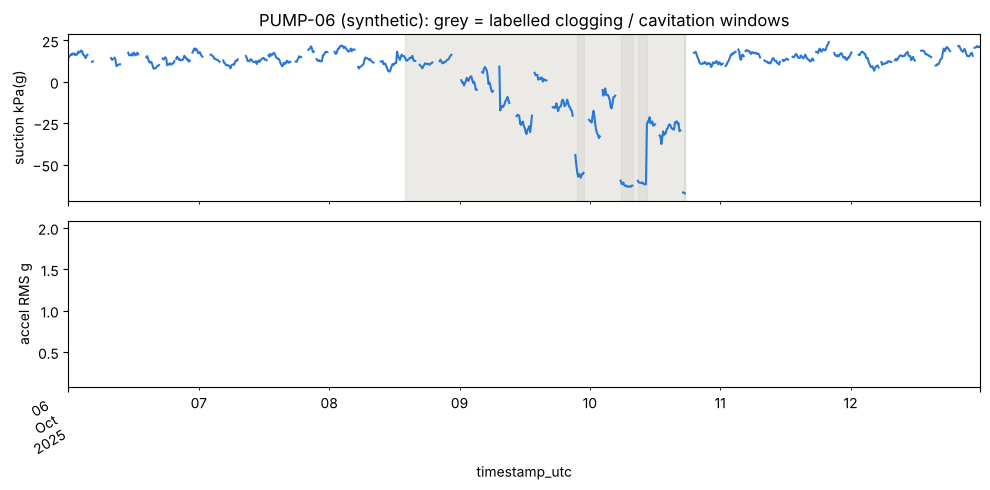

In [4]:
tele = pd.read_csv(os.path.join(D, 'telemetry.csv.gz'))
tele['timestamp_utc'] = pd.to_datetime(tele['timestamp_utc'], utc=True)
p = tele[tele.asset_id == 'PUMP-06'].set_index('timestamp_utc')
run = p.operating_mode == 'RUNNING'
fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
p.suction_pressure_kpa.where(run).resample('10min').mean().plot(ax=ax[0], color='#2a78d6'); ax[0].set_ylabel('suction kPa(g)')
p.vibration_accel_rms_g.where(run).dropna().plot(ax=ax[1], style='.', color='#eb6834', ms=3); ax[1].set_ylabel('accel RMS g')
for _, e in ev[ev.asset_id == 'PUMP-06'].iterrows():
    if e.fault_type in ('SUCTION_STRAINER_CLOGGING', 'CAVITATION'):
        for a in ax: a.axvspan(pd.Timestamp(e.onset_utc), pd.Timestamp(e.end_utc), color='#d9d7d0', alpha=0.5)
ax[0].set_title('PUMP-06 (synthetic): grey = labelled clogging / cavitation windows'); plt.tight_layout()

## Features, baseline, score

In [5]:
import json
par = json.load(open(os.path.join(ROOT, 'baselines', 'results', 'baseline_report.json')))['chosen_parameters']['B1_mode_aware_z']
feat = features_1min(tele)
feat['rows'] = (feat['rows'] * 10).astype('int16')   # 10-s starter rows -> 1-s equivalent
z = B.zscores(B.regime_frame(feat, assets))
val = set(assets[assets.split == 'validation'].asset_id)
pred = B.b1_threshold(z[z.asset_id.isin(val)], k=par['k'], persist=par['persist_min'])   # parameters tuned on train
pred.head()

,asset_id,alert_time_utc,event_class,fault_type,confidence,evidence,recommended_action
0,PUMP-08,2025-09-10T12:38:00Z,MACHINE,SUCTION_STRAINER_CLOGGING,0.558750,B1 mode-aware z: suction_pressure_kpa z=-6.7,Inspect / clean suction strainer.
1,PUMP-08,2025-09-11T01:29:00Z,MACHINE,SUCTION_STRAINER_CLOGGING,0.765694,B1 mode-aware z: suction_pressure_kpa z=-9.2,Inspect / clean suction strainer.
2,PUMP-08,2025-09-11T20:47:00Z,MACHINE,UNKNOWN,0.529839,B1 mode-aware z: fluid_temp_c z=-6.4,Inspect pump.
3,PUMP-08,2025-09-13T00:07:00Z,SENSOR,COMMUNICATION_LOSS,0.050000,B1 mode-aware z: missing rows,Check gateway / network; data gap.
4,PUMP-08,2025-09-13T13:07:00Z,MACHINE,UNKNOWN,0.528737,B1 mode-aware z: fluid_temp_c z=-6.3,Inspect pump.


In [6]:
r = score(pred, pd.read_csv(os.path.join(D, 'events_validation.csv')), assets,
          pd.read_csv(os.path.join(D, 'benign_windows_train_validation.csv')), 'validation')
print(format_report(r))

split=validation assets=1 asset-days=7.0 alerts=6 (bursts=6, invalid types=0)
events scored=4 (unobservable excluded=0)
detected=3  false-alert episodes=0 (nuisance in benign windows=0)  repeats=3 (excess repeat episodes=0)
recall=0.750 precision=1.000 F1=0.857 (false + excess repeat) episodes/asset-day=0.00
timeliness=0.692 fault-type recall=0.500 class recall=0.750
early-warning rate=1.000 median lead to deadline [h]=16.3
COMPOSITE = 73.8 / 100


The score above uses the starter tier (10-s data, one validation pump), so it is not comparable with the official full-tier baseline table in `BENCHMARK_RULES.md`.

## Sandbox what-if (simulation only)

If the strainer is partly clogged, what happens when the seawater pump speed is raised? The condition is *your hypothesis*, not hidden truth. The tool needs the full-tier context file.

In [7]:
full = os.path.join(ROOT, 'data', 'full')
res = what_if(full, 'PUMP-01', '2025-08-12T15:00:00Z', 'speed_setpoint', 0.72, {'clog': 2.0})
print('accepted:', res['accepted'], res['rejection_reasons'])
pd.DataFrame({k: [res['baseline'][k], res['proposed'][k]] for k in ('flow_m3h', 'duty_satisfaction', 'input_kw', 'npsh_margin', 'vib_rms_mm_s', 'risk_proxy')},
             index=['current speed', 'proposed speed']).round(3)

accepted: True []


,flow_m3h,duty_satisfaction,input_kw,npsh_margin,vib_rms_mm_s,risk_proxy
current speed,291.285,1.000,14.826,8.35,0.882,0.176
proposed speed,321.702,1.104,18.332,6.77,0.942,0.188


**Reading the result.** Raising the speed gives more cooling flow than required and costs more electrical power. The NPSH margin falls (faster flow through a clogged strainer means lower inlet pressure) but stays well above the 1.3 limit, so the sandbox accepts the action. It does not fix the cause: cleaning the strainer (`action='clean_strainer'`) is the maintenance answer, and the sandbox shows its cost and stop time. A recommendation to an operator should present both options with this evidence.